# Income Prediction Using TensorFlow and PyTorch


## 1. Install / import libraries
TensorFlow, PyTorch, pandas, scikit-learn and matplotlib are commonly available in Colab. Optuna is installed for the optional tuning section.

In [ ]:
!pip -q install optuna

import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
tf.random.set_seed(SEED)

import torch
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("PyTorch device:", "cuda" if torch.cuda.is_available() else "cpu")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.4/270.4 kB 19.4 MB/s eta 0:00:00
TensorFlow: 2.21.0
PyTorch: 2.11.0+cpu
PyTorch device: cpu


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Load the dataset
In Colab, choose the CSV file from your computer. If the file is already in the current working directory, the upload prompt is skipped.

In [ ]:
DATA_PATH = "/content/drive/MyDrive/AI-ML/Datasets/adult_dataset.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            DATA_PATH = next(iter(uploaded.keys()))
    except Exception:
        pass

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K



Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


## 3. Exploratory Data Analysis (EDA)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,46400.0,NaN,NaN,NaN,38.679116,13.952954,17.0,28.0,37.0,48.0,255.0
workclass,45480,9,Private,32220,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,45485,15,Prof-specialty,5854,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 16

Missing values (top):


,missing_count
workclass,3362
occupation,3357
native-country,2705
hours-per-week,2442
age,2442
fnlwgt,0
education,0
marital-status,0
education-num,0
relationship,0


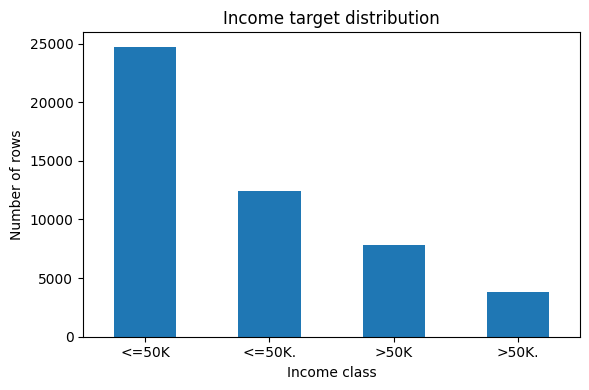

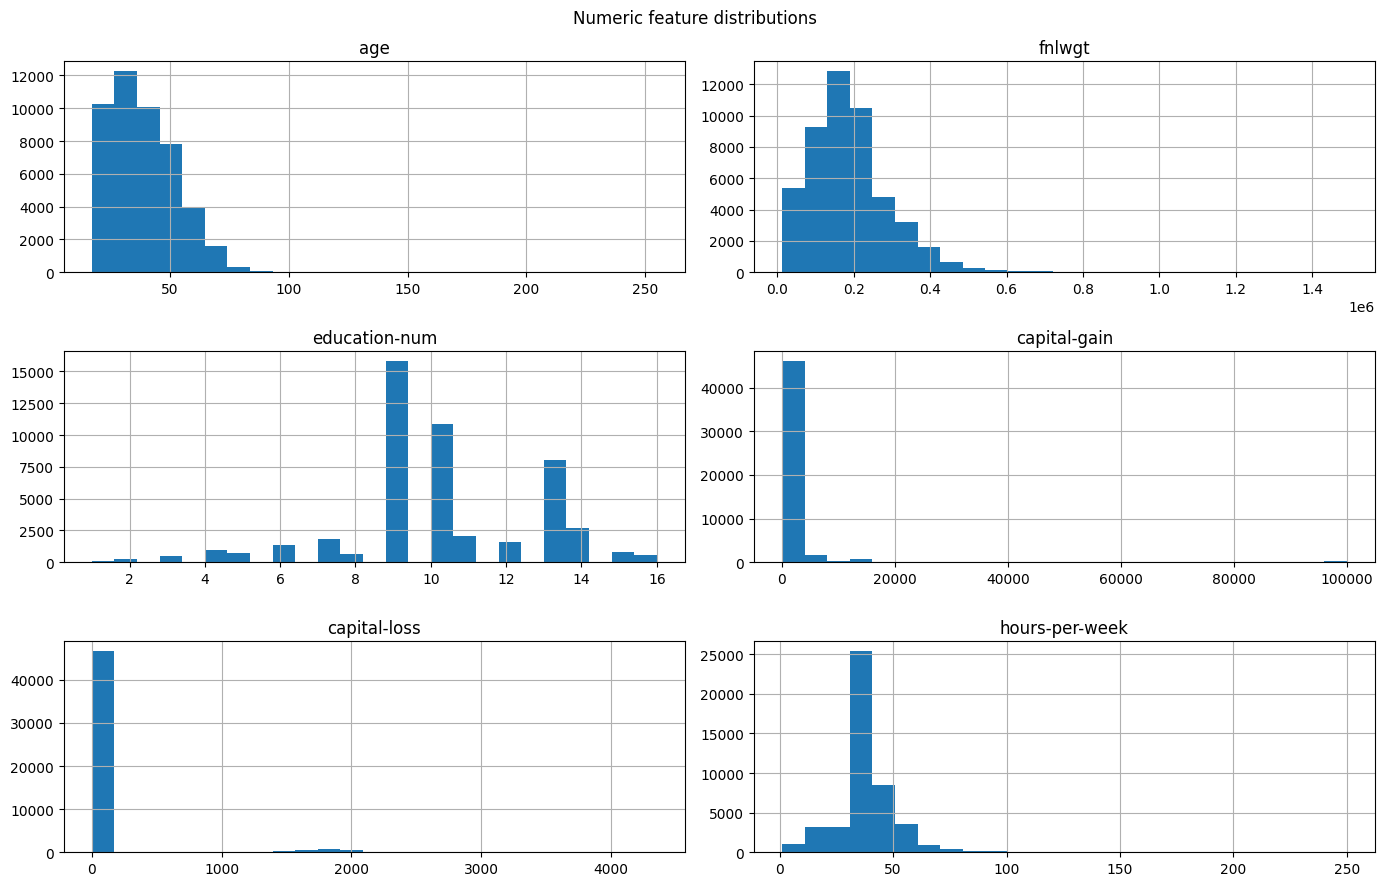

In [ ]:
display(df.info())
display(df.describe(include="all").T)
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values (top):")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

if "income" not in df.columns:
    raise ValueError("Expected target column 'income' was not found. Check the CSV column names.")

plt.figure(figsize=(6, 4))
df["income"].astype(str).value_counts().plot(kind="bar")
plt.title("Income target distribution")
plt.xlabel("Income class")
plt.ylabel("Number of rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

numeric_for_plot = df.select_dtypes(include=np.number).columns.tolist()
if numeric_for_plot:
    df[numeric_for_plot].hist(figsize=(14, 9), bins=25)
    plt.suptitle("Numeric feature distributions")
    plt.tight_layout()
    plt.show()

## 4. Clean and preprocess


In [ ]:
df = df.copy()
df.columns = df.columns.str.strip()

# Normalize text columns and missing-value markers
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"?": pd.NA, "": pd.NA})

# Remove duplicates and rows with missing target
df = df.drop_duplicates().reset_index(drop=True)
df = df.dropna(subset=["income"]).copy()

# 2. Separate features and target
X = df.drop(columns=["income"]).copy()
y_raw = df["income"].astype(str).str.strip()

# Map income labels to binary values
label_map = {
    "<=50K": 0,
    "<=50K.": 0,
    ">50K": 1,
    ">50K.": 1
}

if set(y_raw.unique()).issubset(set(label_map)):
    y = y_raw.map(label_map).astype("int64")
else:
    labels = sorted(y_raw.unique())
    if len(labels) != 2:
        raise ValueError(
            f"Expected a binary income target, but found: {labels}"
        )
    y = y_raw.map({labels[0]: 0, labels[1]: 1}).astype("int64")
    print("Target mapping used:", {labels[0]: 0, labels[1]: 1})

# 3. Convert nullable pandas values to NumPy-compatible missing values
for col in X.columns:
    if (
        pd.api.types.is_object_dtype(X[col].dtype)
        or isinstance(X[col].dtype, pd.StringDtype)
    ):
        X[col] = X[col].astype(object)
        X[col] = X[col].where(pd.notna(X[col]), np.nan)

# 4. Identify numerical and categorical features
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [
    col for col in X.columns if col not in numeric_features
]

# Ensure categorical columns use object dtype
for col in categorical_features:
    X[col] = X[col].astype(object)

# 5. Create OneHotEncoder (supports older and newer sklearn versions)
try:
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

# 6. Build preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
], remainder="drop")

# 7. Split the dataset
SEED = globals().get("SEED", 42)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# 8. Fit on training data and transform both datasets
X_train = np.asarray(
    preprocessor.fit_transform(X_train_raw),
    dtype=np.float32
)

X_test = np.asarray(
    preprocessor.transform(X_test_raw),
    dtype=np.float32
)

y_train_np = y_train.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.int64)

# 9. Display results
print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)
print("Training target shape:", y_train_np.shape)
print("Testing target shape:", y_test_np.shape)

print("\nTraining class balance:")
display(
    y_train.value_counts(normalize=True)
    .sort_index()
    .rename("proportion")
    .to_frame()
)

print("\nMissing values in training matrix:", np.isnan(X_train).sum())
print("Missing values in testing matrix:", np.isnan(X_test).sum())

Training matrix: (39060, 105)
Testing matrix: (9766, 105)
Training target shape: (39060,)
Testing target shape: (9766,)

Training class balance:


,proportion
income,
0,0.76065
1,0.23935



Missing values in training matrix: 0
Missing values in testing matrix: 0


## 5. Define evaluation metrics
Accuracy alone can hide poor performance on a minority class. We also report precision, recall, F1-score, and ROC-AUC.

In [ ]:
def evaluate_predictions(name, y_true, probabilities):
    probabilities = np.asarray(probabilities).reshape(-1)
    predictions = (probabilities >= 0.5).astype("int64")
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }
    print(f"\n{name} classification report:")
    print(classification_report(y_true, predictions, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_true, predictions)
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()
    return results

## 6. TensorFlow model


Epoch 1/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8204 - auc: 0.8562 - loss: 0.3824 - val_accuracy: 0.8519 - val_auc: 0.9067 - val_loss: 0.3182
Epoch 2/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8494 - auc: 0.9027 - loss: 0.3248 - val_accuracy: 0.8573 - val_auc: 0.9114 - val_loss: 0.3110
Epoch 3/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8514 - auc: 0.9059 - loss: 0.3189 - val_accuracy: 0.8573 - val_auc: 0.9126 - val_loss: 0.3086
Epoch 4/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8533 - auc: 0.9085 - loss: 0.3155 - val_accuracy: 0.8583 - val_auc: 0.9130 - val_loss: 0.3077
Epoch 5/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8568 - auc: 0.9101 - loss: 0.3125 - val_accuracy: 0.8594 - val_auc: 0.9136 - val_loss: 0.3070
Epoch 6/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8569 - auc: 0.9114 - loss: 0.3103 - val_accuracy: 0.8602 - val_auc: 0.9133 - val_loss: 0.3076
Epoch 7/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 

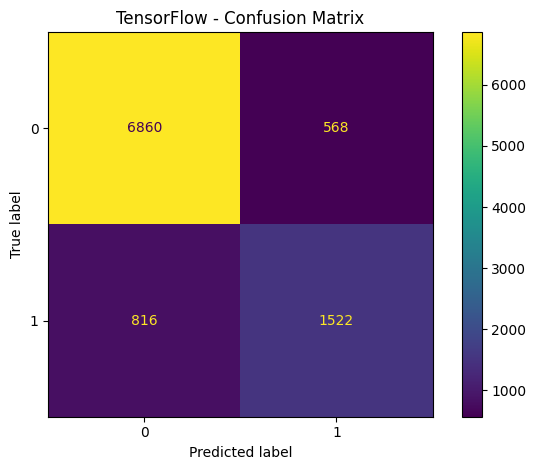

TensorFlow results: {'Model': 'TensorFlow', 'Accuracy': 0.858283841900471, 'Precision': 0.7282296650717703, 'Recall': 0.65098374679213, 'F1-score': 0.6874435411020777, 'ROC-AUC': np.float64(0.9115384509080156)}


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

tf_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(1, activation="sigmoid")
])
tf_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)
tf_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )
]
tf_history = tf_model.fit(
    X_train, y_train_np,
    validation_split=0.15,
    epochs=15,
    batch_size=256,
    callbacks=tf_callbacks,
    verbose=1
)

tf_prob = tf_model.predict(X_test, batch_size=512, verbose=0).ravel()
tf_results = evaluate_predictions("TensorFlow", y_test_np, tf_prob)
print("TensorFlow results:", tf_results)

## 7. PyTorch model


Epoch 01: train_loss=0.3963, val_loss=0.3142
Epoch 02: train_loss=0.3205, val_loss=0.3055
Epoch 03: train_loss=0.3152, val_loss=0.3026
Epoch 04: train_loss=0.3133, val_loss=0.3024
Epoch 05: train_loss=0.3104, val_loss=0.3015
Epoch 06: train_loss=0.3094, val_loss=0.3016
Epoch 07: train_loss=0.3072, val_loss=0.3012
Epoch 08: train_loss=0.3069, val_loss=0.3036
Epoch 09: train_loss=0.3048, val_loss=0.3013
Epoch 10: train_loss=0.3051, val_loss=0.3016
Early stopping.

PyTorch classification report:
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      7428
           1       0.76      0.59      0.67      2338

    accuracy                           0.86      9766
   macro avg       0.82      0.77      0.79      9766
weighted avg       0.85      0.86      0.85      9766



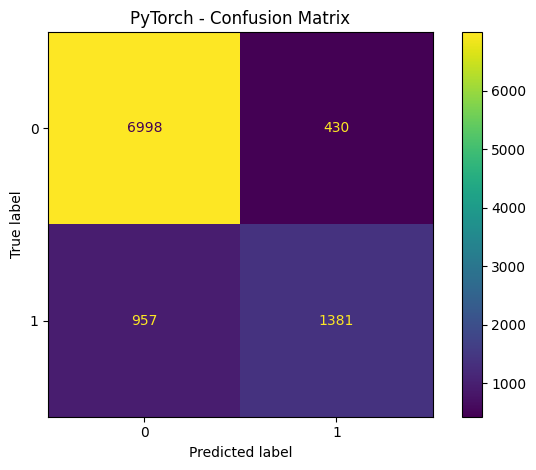

PyTorch results: {'Model': 'PyTorch', 'Accuracy': 0.857976653696498, 'Precision': 0.7625621203754832, 'Recall': 0.5906757912745937, 'F1-score': 0.6657025789346831, 'ROC-AUC': np.float64(0.9122951880683589)}


In [ ]:
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class IncomeNet(nn.Module):
    def __init__(self, input_dim, hidden1=128, hidden2=64, dropout=0.30):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Dropout(dropout / 1.5),
            nn.Linear(hidden2, 1)
        )
    def forward(self, x):
        return self.network(x).squeeze(1)

# Create a validation set from the training data for early stopping.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train_np, test_size=0.15, random_state=SEED,
    stratify=y_train_np
)

def make_loader(X_array, y_array, batch_size=256, shuffle=False):
    ds = TensorDataset(
        torch.from_numpy(np.asarray(X_array, dtype=np.float32)),
        torch.from_numpy(np.asarray(y_array, dtype=np.float32))
    )
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_tr, y_tr, shuffle=True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test_np)

def train_torch_model(model, train_loader, val_loader, epochs=15, lr=1e-3, patience=3):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_loss, best_state, wait = float("inf"), None, 0
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(epochs):
        model.train()
        train_loss_sum, train_count = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(yb)
            train_count += len(yb)

        model.eval()
        val_loss_sum, val_count = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                loss = criterion(model(xb), yb)
                val_loss_sum += loss.item() * len(yb)
                val_count += len(yb)

        train_loss = train_loss_sum / train_count
        val_loss = val_loss_sum / val_count
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        print(f"Epoch {epoch+1:02d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}")

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history

torch_model = IncomeNet(X_train.shape[1])
torch_model, torch_history = train_torch_model(
    torch_model, train_loader, val_loader, epochs=15, lr=1e-3
)

torch_model.eval()
torch_probs = []
with torch.no_grad():
    for xb, _ in test_loader:
        logits = torch_model(xb.to(device))
        torch_probs.extend(torch.sigmoid(logits).cpu().numpy())
torch_probs = np.asarray(torch_probs)
torch_results = evaluate_predictions("PyTorch", y_test_np, torch_probs)
print("PyTorch results:", torch_results)

## 8. Compare TensorFlow and PyTorch


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
TensorFlow,0.8583,0.7282,0.6510,0.6874,0.9115
PyTorch,0.8580,0.7626,0.5907,0.6657,0.9123


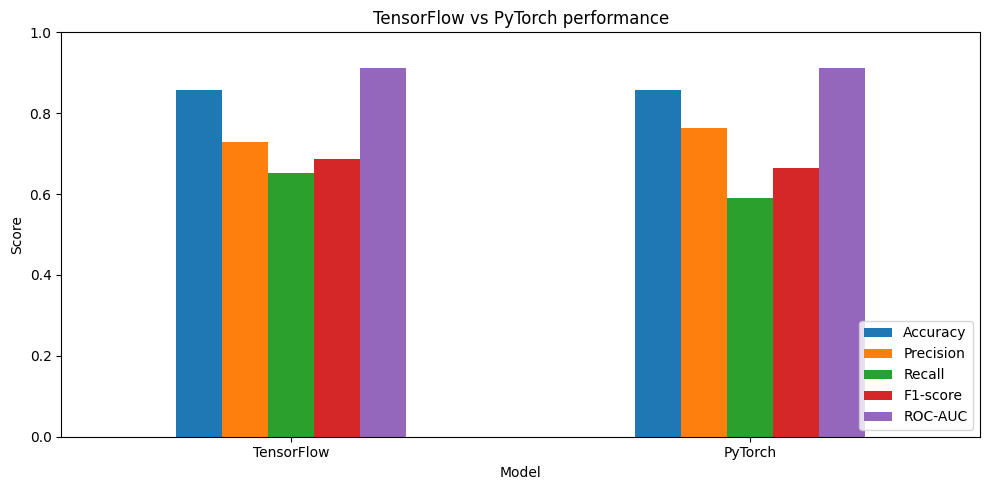

Higher F1-score in this run: TensorFlow
Higher ROC-AUC in this run: PyTorch


In [ ]:
comparison = pd.DataFrame([tf_results, torch_results]).set_index("Model")
display(comparison.round(4))

comparison[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)
plt.title("TensorFlow vs PyTorch performance")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_f1_model = comparison["F1-score"].idxmax()
best_auc_model = comparison["ROC-AUC"].idxmax()
print("Higher F1-score in this run:", best_f1_model)
print("Higher ROC-AUC in this run:", best_auc_model)

## 9. Optional: Optuna hyperparameter tuning (PyTorch)


In [ ]:
import optuna
from sklearn.metrics import f1_score

def objective(trial):
    hidden1 = trial.suggest_categorical("hidden1", [64, 128])
    hidden2 = trial.suggest_categorical("hidden2", [32, 64])
    dropout = trial.suggest_float("dropout", 0.1, 0.4)
    lr = trial.suggest_float("lr", 1e-4, 3e-3, log=True)
    batch_size = trial.suggest_categorical("batch_size", [128, 256])

    trial_train_loader = make_loader(X_tr, y_tr, batch_size=batch_size, shuffle=True)
    trial_val_loader = make_loader(X_val, y_val, batch_size=batch_size)
    model = IncomeNet(X_train.shape[1], hidden1=hidden1, hidden2=hidden2, dropout=dropout)
    model, _ = train_torch_model(
        model, trial_train_loader, trial_val_loader, epochs=6, lr=lr, patience=2
    )

    model.eval()
    val_probs = []
    with torch.no_grad():
        for xb, _ in trial_val_loader:
            val_probs.extend(torch.sigmoid(model(xb.to(device))).cpu().numpy())
    val_preds = (np.asarray(val_probs) >= 0.5).astype(int)
    return f1_score(y_val.astype(int), val_preds, zero_division=0)

# Run only a few trials for a quick baseline comparison.
study = optuna.create_study(direction="maximize", study_name="income_prediction_tuning")
study.optimize(objective, n_trials=5, show_progress_bar=True)

print("Best validation F1:", study.best_value)
print("Best parameters:", study.best_params)
display(study.trials_dataframe().sort_values("value", ascending=False).head())

[I 2026-10-22 18:13:34,628] A new study created in memory with name: income_prediction_tuning


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01: train_loss=0.3659, val_loss=0.3090
Epoch 02: train_loss=0.3163, val_loss=0.3035
Epoch 03: train_loss=0.3133, val_loss=0.3029
Epoch 04: train_loss=0.3101, val_loss=0.3034
Epoch 05: train_loss=0.3090, val_loss=0.3022
Epoch 06: train_loss=0.3071, val_loss=0.3038
[I 2026-10-22 18:13:40,833] Trial 0 finished with value: 0.7021847451130702 and parameters: {'hidden1': 128, 'hidden2': 64, 'dropout': 0.21223908180793397, 'lr': 0.0009508904720830173, 'batch_size': 128}. Best is trial 0 with value: 0.7021847451130702.
Epoch 01: train_loss=0.3516, val_loss=0.3068
Epoch 02: train_loss=0.3164, val_loss=0.3039
Epoch 03: train_loss=0.3136, val_loss=0.3084
Epoch 04: train_loss=0.3109, val_loss=0.3044
Early stopping.
[I 2026-10-22 18:13:43,855] Trial 1 finished with value: 0.6941896024464832 and parameters: {'hidden1': 64, 'hidden2': 32, 'dropout': 0.12989133429231578, 'lr': 0.0020515679818298893, 'batch_size': 128}. Best is trial 0 with value: 0.7021847451130702.
Epoch 01: train_loss=0.3821, 

,number,value,datetime_start,datetime_complete,duration,params_batch_size,params_dropout,params_hidden1,params_hidden2,params_lr,state
0,0,0.702185,2026-10-22 18:13:34.644134,2026-10-22 18:13:40.832969,0 days 00:00:06.188835,128,0.212239,128,64,0.000951,COMPLETE
4,4,0.694228,2026-10-22 18:13:52.347873,2026-10-22 18:13:56.550882,0 days 00:00:04.203009,256,0.191356,128,64,0.000449,COMPLETE
1,1,0.694190,2026-10-22 18:13:40.837945,2026-10-22 18:13:43.855704,0 days 00:00:03.017759,128,0.129891,64,32,0.002052,COMPLETE
2,2,0.693416,2026-10-22 18:13:43.858563,2026-10-22 18:13:48.610899,0 days 00:00:04.752336,256,0.296046,128,64,0.001530,COMPLETE
3,3,0.680868,2026-10-22 18:13:48.615746,2026-10-22 18:13:52.343780,0 days 00:00:03.728034,256,0.249749,64,64,0.001919,COMPLETE


## 10. Train the tuned PyTorch model and evaluate on the test set


Epoch 01: train_loss=0.3700, val_loss=0.3084
Epoch 02: train_loss=0.3166, val_loss=0.3064
Epoch 03: train_loss=0.3133, val_loss=0.3036
Epoch 04: train_loss=0.3105, val_loss=0.3021
Epoch 05: train_loss=0.3091, val_loss=0.3024
Epoch 06: train_loss=0.3067, val_loss=0.3023
Epoch 07: train_loss=0.3046, val_loss=0.3017
Epoch 08: train_loss=0.3030, val_loss=0.3092
Epoch 09: train_loss=0.3022, val_loss=0.3015
Epoch 10: train_loss=0.3003, val_loss=0.3036
Epoch 11: train_loss=0.2991, val_loss=0.3024
Epoch 12: train_loss=0.2968, val_loss=0.3031
Early stopping.

PyTorch + Optuna classification report:
              precision    recall  f1-score   support

           0       0.89      0.92      0.91      7428
           1       0.73      0.65      0.69      2338

    accuracy                           0.86      9766
   macro avg       0.81      0.79      0.80      9766
weighted avg       0.85      0.86      0.86      9766



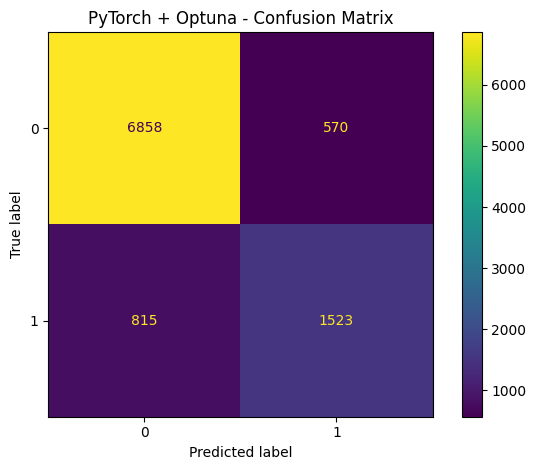

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
TensorFlow,0.8583,0.7282,0.6510,0.6874,0.9115
PyTorch,0.8580,0.7626,0.5907,0.6657,0.9123
PyTorch + Optuna,0.8582,0.7277,0.6514,0.6874,0.9125


In [ ]:
best = study.best_params
best_batch = best["batch_size"]
best_train_loader = make_loader(X_tr, y_tr, batch_size=best_batch, shuffle=True)
best_val_loader = make_loader(X_val, y_val, batch_size=best_batch)

tuned_model = IncomeNet(
    X_train.shape[1],
    hidden1=best["hidden1"],
    hidden2=best["hidden2"],
    dropout=best["dropout"]
)
tuned_model, tuned_history = train_torch_model(
    tuned_model, best_train_loader, best_val_loader,
    epochs=15, lr=best["lr"], patience=3
)

tuned_model.eval()
tuned_probs = []
with torch.no_grad():
    for xb, _ in test_loader:
        tuned_probs.extend(torch.sigmoid(tuned_model(xb.to(device))).cpu().numpy())
tuned_probs = np.asarray(tuned_probs)
tuned_results = evaluate_predictions("PyTorch + Optuna", y_test_np, tuned_probs)

final_comparison = pd.DataFrame([tf_results, torch_results, tuned_results]).set_index("Model")
display(final_comparison.round(4))

## 11. Findings and conclusion (complete after running)
Use the real metric values printed above to complete this section. Do not invent values.

- **Dataset and preprocessing:** The dataset contains census-related demographic and employment features. Missing values were imputed; numeric features were scaled; categorical features were one-hot encoded. The target `income` was converted into a binary label.
- **Evaluation:** Compare accuracy, precision, recall, F1-score, and ROC-AUC. F1-score balances precision and recall; ROC-AUC evaluates how well the model ranks the two classes across thresholds.
- **TensorFlow vs PyTorch:** Both frameworks can implement similar feed-forward neural networks. Differences in results can come from initialization, training details, and optimization rather than the framework alone.
- **Optuna:** Compare the tuned model's test metrics with the original PyTorch model. Tuning improves performance only if the measured results support that conclusion.
- **Limitations:** The Adult dataset may contain social and historical biases. Predictive performance does not imply that income prediction should be used for high-impact decisions about individuals.

